# Modelagem da atmosfera

In [3]:
import numpy as np
import matplotlib.pyplot as plt

## Gravidade

$$ g(h) = g_0\left(\frac{R}{R+h}\right)^2$$

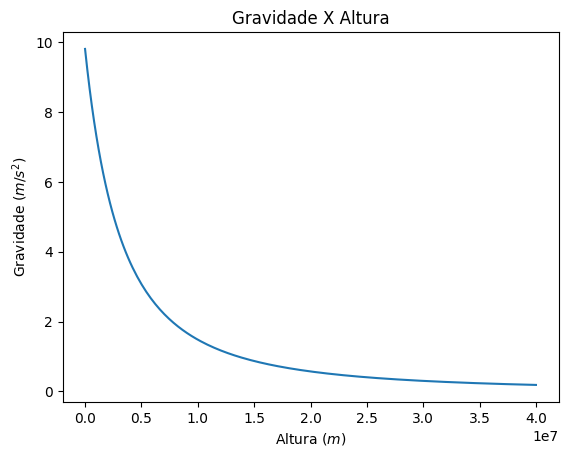

In [4]:
R = 6_356_766 # m
g0 = 9.80665 # m/s^2

def gravidade_efetiva(h):
    return g0 * ((R / (R+h)) ** 2)

x = np.linspace(0, 40_000_000, 200)
y = gravidade_efetiva(x)

plt.plot(x, y)
plt.xlabel("Altura ($m$)")
plt.ylabel("Gravidade ($m/s^2$)")
plt.title("Gravidade X Altura")
plt.show()

## Temperatura

$$ T(h)=T_0+ \sum_{j=0}^{i-1} \beta_j\,(h_{j+1}-h_j) + \beta_i\,(h-h_i), \qquad h_i<h<h_{i+1} $$

$$ T(h)=T_0+\int_{h_0}^{h}\beta(z)\,dz $$

$$ \begin{aligned} h_0 &= 0~\text{km},\\ h_1 &= 11~\text{km},\\ h_2 &= 20~\text{km},\\ h_3 &= 32~\text{km},\\ h_4 &= 47~\text{km},\\ h_5 &= 51~\text{km},\\ h_6 &= 71~\text{km},\\ h_7 &= 86~\text{km}, \end{aligned} \qquad \begin{aligned} \beta_0 &= -6.5,\\ \beta_1 &= 0,\\ \beta_2 &= 1.0,\\ \beta_3 &= 2.8,\\ \beta_4 &= 0,\\ \beta_5 &= -2.8,\\ \beta_6 &= -2.0. \end{aligned} $$

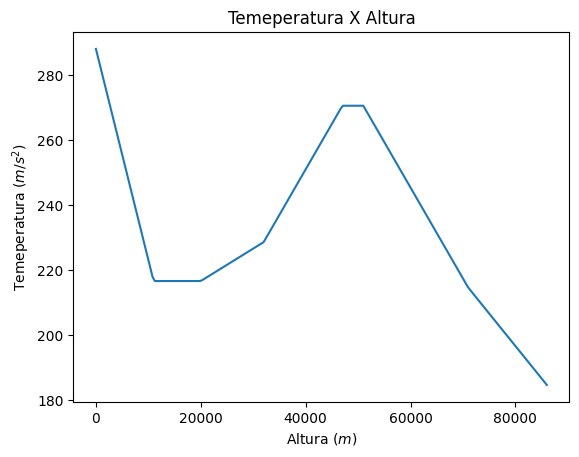

In [23]:
T0 = 288.15 # K

alturas = [
    0,
    11_000,
    20_000,
    32_000,
    47_000,
    51_000,
    71_000,
    86_000,
]

beta = np.array([
    -6.5,
    0.0,
    1.0,
    2.8,
    0.0,
    -2.8,
    -2.0,
    0.0
]) / 1000

def temperatura(h):
    t = T0
    # print(t)
    
    i = np.sum([(x <= h) for x in alturas]) - 1
    # print([(x <= h) for x in alturas])
    # print(i)
    
    for j in range(0, i):
        
        # print(i, i+1)
        # print(f"{hb[i][1]} * ({hb[i+1][0]} - {hb[i][0]}) = {hb[i][1] * (hb[i+1][0] - hb[i][0])}")
        
        t += beta[j] * (alturas[j+1] - alturas[j])
        # print(t)
    
    
    t += beta[i] * (h - alturas[i])
    # print(t)
    
    return t

temperatura(13_000)


x = np.linspace(0, 86_000, 200)
y = [temperatura(xi) for xi in x]

plt.plot(x, y)
plt.xlabel("Altura ($m$)")
plt.ylabel("Temeperatura ($m/s^2$)")
plt.title("Temeperatura X Altura")
plt.show()

## Densidade

$$ \frac{d\rho}{dh} = -\rho(h)\left( \frac{g(h)\,M_m}{R_g\,T(h)} + \frac{1}{T(h)}\,\frac{dT}{dh} \right) $$


$$ \frac{d\rho}{dh} = -\rho(h)f(h) $$

$$
ln(\rho(h)) = -[
\frac{R^2 g_0 M_m}{R_g}
\cdot
\frac{
\beta(R+h)\ln\left(
\frac{-\beta h_i+\beta h+C}{R+h}
\right)
+R\beta+\beta h_i-C
}{
(R+h)\left(\beta R+\beta h_i-C\right)^2
}
+ ln(T(h)) + K_i]
\text{, caso }

\frac{dT}{dh} \neq 0
$$

$$
ln(\rho(h)) = -[
-\frac{M_m g_0 R^2}{R_g\,T(h)(R+h)}
+K_i
]

\text{, caso }

\frac{dT}{dh} = 0
$$

In [ ]:
Mm = 28.9644e-3 # kg/mol
Rg = 8.31446261815324 # J/mol*K

def dt_dh(h):
    i = np.sum([x <= h for x in alturas]) - 1
    return beta[i]

# K = [
#     K0,
#     K1,
#     K2,
#     K3,
#     K4,
#     K5,
#     K6,
# ]

rho0 = 1.225  # kg/m³

A = R**2 * g0 * Mm / Rg

def F(h, i):
    b = beta[i]
    hi = alturas[i]
    T = temperatura(h)

    if b != 0:
        C = temperatura(hi) - b * hi

        return (
            (R**2 * g0 * Mm / Rg)
            * (
                b * (R + h)
                * np.log(
                    (-b * hi + b * h + C) / (R + h)
                )
                + R * b
                + b * hi
                - C
            )
            / (
                (R + h)
                * (b * R + b * hi - C)**2
            )
            + np.log(T)
        )

    else:
        return (
            -Mm * g0 * R**2
            / (Rg * T * (R + h))
        )
        
K = np.zeros(len(beta))

K[0] = -np.log(rho0) - F(alturas[0], 0)

for i in range(1, len(beta)):
    K[i] = (
        K[i-1]
        + F(alturas[i], i-1)
        - F(alturas[i], i)
    )


print(*[f"K{i} = {k}" for i, k in enumerate(K)], sep="\n")

def rho(h):
    i = np.sum([x <= h for x in alturas]) - 1

    k = K[i]
    # print(k)

    # print("h =", h)
    # print("i =", i)
    # print("beta =", beta[i])
    # print("T =", temperatura(h))
    # print("K =", K[i])
    # print("F =", F(h, i))
    # print("expoente =", -(F(h, i) + K[i]))


    return np.exp(
        -(F(h, i) + k)
    )

K0 = -52.487466456953086
K1 = 1001.6476924457172
K2 = 337.4265663667737
K3 = 118.58606842204695
K4 = 804.3204132653703
K5 = -96.22920243876868
K6 = -134.26530124940464
K7 = 1171.5365004302143


In [112]:
# i = 0
# while rho(i) != 0:
#     i+= 1
    
# print(i)

rho(11_000)

np.float64(0.3649157471824279)

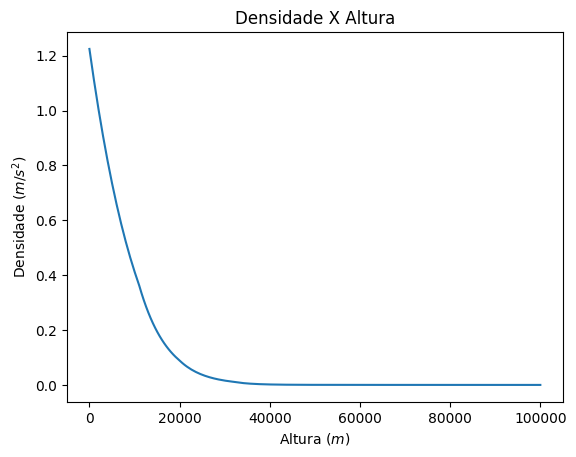

In [111]:
x = np.linspace(0, 100_000, 200)
y = [rho(xi) for xi in x]

plt.plot(x, y)
plt.xlabel("Altura ($m$)")
plt.ylabel("Densidade ($m/s^2$)")
plt.title("Densidade X Altura")
plt.show()